In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from matplotlib.ticker import FixedLocator, NullFormatter, FormatStrFormatter
import sympy as sp
from matplotlib.ticker import ScalarFormatter
import scipy.odr as odr
from matplotlib.lines import Line2D

In [2]:
R_moon=1737400 #m
g_moon=1.62 #m/s^2
secx=-79.004337 #dec deg
secy=3.413069 #dec deg
D_sec=61.68 #m, diameter of gromit
solar_incidence_angle=55.26 #deg
boulder_density=2875 #kg/m^3 http://www.psrd.hawaii.edu/CosmoSparks/July12/Lunar-rock-densities.html#:~:text=For%20a%20typical%20lunar%20mare,%C2%B150%20kg%2Fm3.
angles=[30,45] #input all angles in degrees, they'll get converted to radians inside the functions. This list can be as long as you want
regime='strength' #only works for str regime right now
target_materials=['hard rock','regolith']

In [3]:
#uncertainties
# unc_lengths=0.88 #m, 1 px
unc_lengths=0.88/2 #m, 0.5 px
# unc_positions=0.000005 #dec deg (also 1 px)
unc_positions=0.000005/2 #dec deg (also 0.5 px)

unc_secx=unc_positions
unc_secy=unc_positions
unc_D_sec=unc_lengths

num_terts=14

In [4]:
data = {'ID': [1,2,3,4,5,13,14,15,16,17,18,19,20,21],
        'tert x [dec deg]': [-79.002714,-79.00384,-79.005072,-79.004056,-79.007158,-79.003403,-79.008989,-79.002921,-79.001253,-79.008125,-79.004889,-79.006001,-79.003238,-79.010171],
        'tert y [dec deg]': [3.422149,3.423758,3.422867,3.428623,3.430601,3.429957,3.424349,3.429984,3.430003,3.427867,3.42671,3.426679,3.426739,3.436394],
        'tert shadow length [m]': [2.86,2.45,3.62,3.08,2.58,2.89,1.84,2.60,2.88,1.83,1.95,1.65,1.79,2.56],
        'tert diam long axis [m]': [10.84,7.07,8.07,11.12,9.79,7.26,4.04,6.74,7.78,4.99,4.46,4.82,3.95,6.59],
        'tert diam short axis [m]': [4.54,4.99,6.36,5.67,5.43,4.65,2.87,4.02,6.45,3.72,3.50,3.32,3.10,4.85],
        'tert boulder': [True,True,True,True,False,False,True,True,False,False,True,True,False,False], #true or false
        'boulder ID': [2,4,3,5,None,None,7,8,None,None,10,11,None,None],
        'boulder x [dec deg]': [-79.002464,-79.00377,-79.005085,-79.003716,None,None,-79.009068,-79.002756,None,None,-79.004872,-79.006067,None,None],
        'boulder y [dec deg]': [3.422944,3.424182,3.423497,3.429578,None,None,3.424564,3.430467,None,None,3.426856,3.42724,None,None],
        'boulder diam [m]': [4.950768,4.48581,3.612041,2.907745,None,None,3.263614,2.455896,None,None,2.468819,1.796671,None,None]}
df = pd.DataFrame.from_dict(data)
display(df)

,ID,tert x [dec deg],tert y [dec deg],tert shadow length [m],tert diam long axis [m],tert diam short axis [m],tert boulder,boulder ID,boulder x [dec deg],boulder y [dec deg],boulder diam [m]
0,1,-79.002714,3.422149,2.86,10.84,4.54,True,2.0,-79.002464,3.422944,4.950768
1,2,-79.003840,3.423758,2.45,7.07,4.99,True,4.0,-79.003770,3.424182,4.485810
2,3,-79.005072,3.422867,3.62,8.07,6.36,True,3.0,-79.005085,3.423497,3.612041
3,4,-79.004056,3.428623,3.08,11.12,5.67,True,5.0,-79.003716,3.429578,2.907745
4,5,-79.007158,3.430601,2.58,9.79,5.43,False,NaN,NaN,NaN,NaN
5,13,-79.003403,3.429957,2.89,7.26,4.65,False,NaN,NaN,NaN,NaN
6,14,-79.008989,3.424349,1.84,4.04,2.87,True,7.0,-79.009068,3.424564,3.263614
7,15,-79.002921,3.429984,2.60,6.74,4.02,True,8.0,-79.002756,3.430467,2.455896
8,16,-79.001253,3.430003,2.88,7.78,6.45,False,NaN,NaN,NaN,NaN
9,17,-79.008125,3.427867,1.83,4.99,3.72,False,NaN,NaN,NaN,NaN


In [5]:
unc = {
    'UNC tert x [dec deg]': [unc_positions]*num_terts,
    'UNC tert y [dec deg]': [unc_positions]*num_terts,
    'UNC tert shadow length [m]': [unc_lengths]*num_terts,
    'UNC tert diam long axis [m]': [unc_lengths]*num_terts,
    'UNC tert diam short axis [m]': [unc_lengths]*num_terts,
    'UNC boulder x [dec deg]': [unc_positions]*num_terts,
    'UNC boulder y [dec deg]': [unc_positions]*num_terts,
    'UNC boulder diam [m]': [unc_lengths]*num_terts
    }
udf = pd.DataFrame.from_dict(unc)
display(udf)

,UNC tert x [dec deg],UNC tert y [dec deg],UNC tert shadow length [m],UNC tert diam long axis [m],UNC tert diam short axis [m],UNC boulder x [dec deg],UNC boulder y [dec deg],UNC boulder diam [m]
0,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
1,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
2,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
3,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
4,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
5,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
6,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
7,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
8,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44
9,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44


In [6]:
if regime!='strength':
  print('THIS ONLY WORKS FOR THE STRENGTH REGIME RIGHT NOW, GRAVITY REGIME ENJOYERS GET OUT OF HERE')

In [7]:
def calc_tert_depth(tert_shadow_length):
  return tert_shadow_length/(np.tan(math.radians(solar_incidence_angle)))

def calc_tert_volume(tert_depth,tert_long_axis_diam,tert_short_axis_diam): #volume of half an ellipsoid where a & b are the diameters of the long and short axes, and c is the depth from the surface= 2/3 (pi a/2*b/2*c)= 1/6 pi*a*b*c
  return tert_depth*tert_long_axis_diam*tert_short_axis_diam/6*np.pi

def calc_boulder_volume(boulder_diam):
  return 4/3*np.pi*(boulder_diam/2)**3

def calc_tert_to_boulder_volume_ratio(tert_volume,boulder_volume):
  return tert_volume/boulder_volume

def calc_range(lon1, lat1, lon2, lat2): #haversine formula, code adapted from https://community.esri.com/t5/coordinate-reference-systems-blog/distance-on-a-sphere-the-haversine-formula/ba-p/902128
  phi_1 = math.radians(lat1)
  phi_2 = math.radians(lat2)

  delta_phi = math.radians(lat2 - lat1)
  delta_lambda = math.radians(lon2 - lon1)

  a = math.sin(delta_phi / 2.0) ** 2 + math.cos(phi_1) * math.cos(phi_2) * math.sin(delta_lambda / 2.0) ** 2

  c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))

  return R_moon * c  # output distance in meters

def calc_delta_KE(boulder_volume,v_projectile_out_of_sec,v_boulder_out_of_tert):
  return 0.5*boulder_density*boulder_volume*(v_projectile_out_of_sec**2-v_boulder_out_of_tert**2)

In [8]:
#this block contains the SHH scaling relations
def calc_v_projectile(range,D_big,theta): #eg, if range from sec center to tert center, then D_big would be D_sec, and we get the velocity of the projectile that comes out of the secondary and makes the tertiary
  theta=math.radians(theta)
  delta=(range-D_big/4)/(2*R_moon) #delta is shorthand for that term to make the velocity eqn look prettier. It’s the surface arc dist b/n the sec and tert, converted to an ang separation on the moon accounting for the finite size of the sec
  return np.sqrt((R_moon*g_moon*np.tan(delta))/((np.cos(theta))**2*np.tan(delta)+np.sin(theta)*np.cos(theta)))

def calc_D_boulder(D_tert,v_projectile,theta,target_type):
  theta=math.radians(theta)
  if target_type=='hard rock':
    return (6.79*D_tert)/((v_projectile*np.sin(theta))**0.551) #SHH consts
  elif target_type=='regolith':
    return (1.047*D_tert)/((v_projectile*np.sin(theta))**0.41) #SHH consts
  else:
    print('target type',target_type,'not recognized. must be either "hard rock" or "regolith"')
    return None

In [9]:
# this block is propagating the unc on all values

def _to_numpy(arr):
    return np.asarray(arr, dtype=float)

def _nan_if_none(x):
    return np.nan if x is None else x

def propagate_sigma(expr, vars_, vals_dict, sigmas_dict):
    """
    First-order propagation:
      sigma_f^2 = sum_i (df/dx_i)^2 * sigma_xi^2
    assuming independence.
    """
    #build derivative lambdas once per call
    derivs = [sp.lambdify(vars_, sp.diff(expr, v), "numpy") for v in vars_]

    #build value arrays in var order
    X = [vals_dict[v] for v in vars_]

    sig2 = 0.0
    for v, dlam in zip(vars_, derivs):
        s = sigmas_dict[v]
        dfdv = dlam(*X)
        sig2 = sig2 + (dfdv * s) ** 2

    return np.sqrt(sig2)

#tert depth: depth = L/tan(i)
L = sp.Symbol("L", positive=True)
i_deg = float(solar_incidence_angle)
depth_expr = L / sp.tan(sp.rad(i_deg))

#tert volume: V = pi/6 * d*a*b
d, a, b = sp.symbols("d a b", positive=True)
tert_vol_expr = sp.pi/6 * d * a * b

#boulder volume: Vb = pi/6 * D^3
D = sp.Symbol("D", positive=True)
bould_vol_expr = sp.pi/6 * D**3

#volume ratio: Vr = Vt/Vb
Vt, Vb = sp.symbols("Vt Vb", positive=True)
ratio_expr = Vt / Vb

#haversine eqn yielding range (degrees in, meters out)
lon1, lat1, lon2, lat2 = sp.symbols("lon1 lat1 lon2 lat2", real=True)
R = sp.symbols("R", positive=True, real=True)

phi1 = sp.rad(lat1)
phi2 = sp.rad(lat2)
dphi = sp.rad(lat2 - lat1)
dlmb = sp.rad(lon2 - lon1)

hav_a = sp.sin(dphi/2)**2 + sp.cos(phi1)*sp.cos(phi2)*sp.sin(dlmb/2)**2
hav_c = 2 * sp.atan2(sp.sqrt(hav_a), sp.sqrt(1 - hav_a))
range_expr = R * hav_c

#SHH projectile velocity
rng, Dbig, g, theta = sp.symbols("rng Dbig g theta", positive=True, real=True)
delta = (rng - Dbig/4) / (2*R)
num = R*g*sp.tan(delta)
den = (sp.cos(theta)**2)*sp.tan(delta) + sp.sin(theta)*sp.cos(theta)
v_expr = sp.sqrt(num/den)

#boulder diameter relations
Dtert, vproj, K, p = sp.symbols("Dtert vproj K p", positive=True, real=True)
Db_expr = K * Dtert / ( (vproj*sp.sin(theta))**p )

#delta KE
rho = sp.Symbol("rho", positive=True, real=True)
v1, v2 = sp.symbols("v1 v2", real=True)
dKE_expr = sp.Rational(1,2) * rho * Vb * (v1**2 - v2**2)


#put uncertainty columns into udf
def build_udf_uncertainties(df, udf):
    n = len(df)

    #input uncertainties you already have
    sig_lon_t = _to_numpy(udf["UNC tert x [dec deg]"])
    sig_lat_t = _to_numpy(udf["UNC tert y [dec deg]"])
    sig_L      = _to_numpy(udf["UNC tert shadow length [m]"])
    sig_a      = _to_numpy(udf["UNC tert diam long axis [m]"])
    sig_b      = _to_numpy(udf["UNC tert diam short axis [m]"])

    sig_lon_b = _to_numpy([_nan_if_none(x) for x in udf["UNC boulder x [dec deg]"]])
    sig_lat_b = _to_numpy([_nan_if_none(x) for x in udf["UNC boulder y [dec deg]"]])
    sig_D_b   = _to_numpy([_nan_if_none(x) for x in udf["UNC boulder diam [m]"]])

    #consts + their uncs
    sig_secx = float(unc_secx)
    sig_secy = float(unc_secy)
    sig_Dsec = float(unc_D_sec)


    #tert depth [m]
    # depth(L)
    depth_vals = _to_numpy(df["tert shadow length [m]"])
    udf["UNC tert depth [m]"] = propagate_sigma(
        depth_expr, [L],
        {L: depth_vals},
        {L: sig_L}
    )


    #sec center to tert center [m] : range(secx,secy, lon_t,lat_t)
    lon_t = _to_numpy(df["tert x [dec deg]"])
    lat_t = _to_numpy(df["tert y [dec deg]"])
    secx_arr = np.full(n, float(secx))
    secy_arr = np.full(n, float(secy))
    R_arr    = np.full(n, float(R_moon))

    udf["UNC sec center to tert center [m]"] = propagate_sigma(
        range_expr, [lon1, lat1, lon2, lat2, R],
        {lon1: secx_arr, lat1: secy_arr, lon2: lon_t, lat2: lat_t, R: R_arr},
        {
            lon1: np.full(n, sig_secx),
            lat1: np.full(n, sig_secy),
            lon2: sig_lon_t,
            lat2: sig_lat_t,
            R:    np.zeros(n),  #treating R as exact
        }
    )


    #tert volume [m^3]
    depth_df = _to_numpy(df["tert depth [m]"])
    a_df     = _to_numpy(df["tert diam long axis [m]"])
    b_df     = _to_numpy(df["tert diam short axis [m]"])

    udf["UNC tert volume [m^3]"] = propagate_sigma(
        tert_vol_expr, [d, a, b],
        {d: depth_df, a: a_df, b: b_df},
        {d: _to_numpy(udf["UNC tert depth [m]"]), a: sig_a, b: sig_b}
    )

    #velocity from sec to tert [m/s] for each theta in angles
    rng_sec_tert = _to_numpy(df["sec center to tert center [m]"])
    sig_rng_sec_tert = _to_numpy(udf["UNC sec center to tert center [m]"])

    for ang in angles:
        th = math.radians(ang)
        th_arr = np.full(n, th)
        g_arr  = np.full(n, float(g_moon))
        Dbig_arr = np.full(n, float(D_sec))

        udf[f"UNC velocity from sec to tert [m/s], theta={ang} deg"] = propagate_sigma(
            v_expr, [rng, Dbig, theta, R, g],
            {rng: rng_sec_tert, Dbig: Dbig_arr, theta: th_arr, R: R_arr, g: g_arr},
            {
                rng:  sig_rng_sec_tert,
                Dbig: np.full(n, sig_Dsec),
                theta: np.zeros(n),  #treating theta as exact
                R: np.zeros(n),
                g: np.zeros(n),
            }
        )

    #calculated fragment diameter [m] for each theta/material
    Dtert_df = _to_numpy(df["tert diam short axis [m]"])
    sig_Dtert = sig_b

    for material in target_materials:
        if material == "hard rock":
            Kval, pval = 6.79, 0.551 #SHH consts
        elif material == "regolith":
            Kval, pval = 1.047, 0.41 #SHH consts
        else:
            print('this only works for hard rock or regolith right now')
            continue

        for ang in angles:
            th = math.radians(ang)
            th_arr = np.full(n, th)

            vcol = f"velocity from sec to tert [m/s], theta={ang} deg"
            sigvcol = f"UNC velocity from sec to tert [m/s], theta={ang} deg"
            v_df = _to_numpy(df[vcol])
            sig_v = _to_numpy(udf[sigvcol])

            udf[f"UNC calculated fragment diameter [m] theta={ang} deg, material={material}"] = propagate_sigma(
                Db_expr, [Dtert, vproj, theta, K, p],
                {Dtert: Dtert_df, vproj: v_df, theta: th_arr, K: np.full(n, Kval), p: np.full(n, pval)},
                {Dtert: sig_Dtert, vproj: sig_v, theta: np.zeros(n), K: np.zeros(n), p: np.zeros(n)}
            )

    #boulder volume [m^3]
    D_bould_df = _to_numpy(df["boulder diam [m]"])
    udf["UNC boulder volume [m^3]"] = propagate_sigma(
        bould_vol_expr, [D],
        {D: D_bould_df},
        {D: sig_D_b}
    )

    #tert center to boulder center [m]
    lon_b = _to_numpy(df["boulder x [dec deg]"])
    lat_b = _to_numpy(df["boulder y [dec deg]"])

    udf["UNC tert center to boulder center [m]"] = propagate_sigma(
        range_expr, [lon1, lat1, lon2, lat2, R],
        {lon1: lon_t, lat1: lat_t, lon2: lon_b, lat2: lat_b, R: R_arr},
        {lon1: sig_lon_t, lat1: sig_lat_t, lon2: sig_lon_b, lat2: sig_lat_b, R: np.zeros(n)}
    )

    #tertiary:boulder volume ratio
    Vt_df = _to_numpy(df["tert volume [m^3]"])
    Vb_df = _to_numpy(df["boulder volume [m^3]"])

    udf["UNC tertiary:boulder volume ratio"] = propagate_sigma(
        ratio_expr, [Vt, Vb],
        {Vt: Vt_df, Vb: Vb_df},
        {Vt: _to_numpy(udf["UNC tert volume [m^3]"]), Vb: _to_numpy(udf["UNC boulder volume [m^3]"])}
    )

    #velocity from tert to boulder [m/s]
    rng_t_b = _to_numpy(df["tert center to boulder center [m]"])
    sig_rng_t_b = _to_numpy(udf["UNC tert center to boulder center [m]"])

    for ang in angles:
        th = math.radians(ang)
        th_arr = np.full(n, th)
        g_arr  = np.full(n, float(g_moon))

        udf[f"UNC velocity from tert to boulder [m/s], theta={ang} deg"] = propagate_sigma(
            v_expr, [rng, Dbig, theta, R, g],
            {rng: rng_t_b, Dbig: Dtert_df, theta: th_arr, R: R_arr, g: g_arr},
            {
                rng:  sig_rng_t_b,
                Dbig: sig_Dtert,
                theta: np.zeros(n),
                R: np.zeros(n),
                g: np.zeros(n),
            }
        )

    #KE lost while forming the tert [J]
    rho_arr = np.full(n, float(boulder_density))
    Vb_sig = _to_numpy(udf["UNC boulder volume [m^3]"])

    for ang in angles:
        v1_df = _to_numpy(df[f"velocity from sec to tert [m/s], theta={ang} deg"])
        v2_df = _to_numpy(df[f"velocity from tert to boulder [m/s], theta={ang} deg"])

        sig_v1 = _to_numpy(udf[f"UNC velocity from sec to tert [m/s], theta={ang} deg"])
        sig_v2 = _to_numpy(udf[f"UNC velocity from tert to boulder [m/s], theta={ang} deg"])

        udf[f"UNC KE lost while forming the tert [J], theta={ang} deg"] = propagate_sigma(
            dKE_expr, [rho, Vb, v1, v2],
            {rho: rho_arr, Vb: Vb_df, v1: v1_df, v2: v2_df},
            {rho: np.zeros(n), Vb: Vb_sig, v1: sig_v1, v2: sig_v2}
        )

    return udf


In [10]:
def build_df(df):
  starting_loc=df.columns.get_loc('tert shadow length [m]')
  tert_depths=[]
  for shadow_length in list(df['tert shadow length [m]']):
    tert_depths.append(calc_tert_depth(shadow_length))
  df.insert(starting_loc+1, 'tert depth [m]', tert_depths, True)

  starting_loc=df.columns.get_loc('tert diam short axis [m]')
  ranges_sec_to_tert=[]
  for lon2, lat2 in zip(list(df['tert x [dec deg]']),list(df['tert y [dec deg]'])):
    ranges_sec_to_tert.append(calc_range(secx, secy, lon2, lat2))
  df.insert(starting_loc+1, 'sec center to tert center [m]', ranges_sec_to_tert, True)

  tert_volumes=[]
  for d,l,s in zip(list(df['tert depth [m]']),list(df['tert diam long axis [m]']),list(df['tert diam short axis [m]'])):
    tert_volumes.append(calc_tert_volume(d,l,s))
  df.insert(starting_loc+2, 'tert volume [m^3]', tert_volumes, True)

  #at positions 9,10
  i=1
  for angle in angles:
    velos=[]
    for range in list(df['sec center to tert center [m]']):
      velos.append(calc_v_projectile(range,D_sec,angle))
    df.insert(starting_loc+2+i, 'velocity from sec to tert [m/s], theta='+str(angle)+' deg', velos, True)
    i+=1

  starting_loc=df.columns.get_loc('tert boulder') #figuring out where to put these next columns, because we have a variable number of angles
  i=0
  for material in target_materials:
    for angle in angles:
      diams=[]
      for D_tert,v_projectile in zip(list(df['tert diam short axis [m]']),list(df['velocity from sec to tert [m/s], theta='+str(angle)+' deg'])): #using short axis of the terts for the calcs
        diams.append(calc_D_boulder(D_tert,v_projectile,angle,material))
      df.insert(starting_loc+i, 'calculated fragment diameter [m] theta='+str(angle)+' deg, material='+material, diams, True)
      i+=1

  loc=df.columns.get_loc('boulder diam [m]')+1 #figuring out where to put the next column, because we have a variable number of angles
  volumes=[]
  for diam in list(df['boulder diam [m]']):
    volumes.append(calc_boulder_volume(diam))
  df.insert(loc, 'boulder volume [m^3]', volumes, True)

  ranges_tert_to_boulder=[]
  for lon1, lat1, lon2, lat2 in zip(list(df['tert x [dec deg]']),list(df['tert y [dec deg]']),list(df['boulder x [dec deg]']),list(df['boulder y [dec deg]'])):
    ranges_tert_to_boulder.append(calc_range(lon1, lat1, lon2, lat2))
  df.insert(loc+1, 'tert center to boulder center [m]', ranges_tert_to_boulder, True)

  volume_ratios=[]
  smaller_than_1=[]
  for tert_volume, boulder_volume in zip(list(df['tert volume [m^3]']),list(df['boulder volume [m^3]'])):
    volume_ratio=calc_tert_to_boulder_volume_ratio(tert_volume, boulder_volume)
    volume_ratios.append(volume_ratio)
    if volume_ratio<1:
      smaller_than_1.append(True)
    elif volume_ratio>=1:
      smaller_than_1.append(False)
    else:
      smaller_than_1.append(math.nan)
  df.insert(loc+2, 'tertiary:boulder volume ratio', volume_ratios, True)
  df.insert(loc+3, 'tertiary:boulder volume ratio<1?', smaller_than_1, True)

  i=1
  for angle in angles:
    velos=[]
    for range,D_tert in zip(list(df['tert center to boulder center [m]']),list(df['tert diam short axis [m]'])): #using short axis of the terts for the calcs
      velos.append(calc_v_projectile(range,D_tert,angle))
    df.insert(loc+3+i, 'velocity from tert to boulder [m/s], theta='+str(angle)+' deg', velos, True)
    i+=1

  for angle in angles:
    KEs=[]
    for boulder_volume,v_projectile_out_of_sec,v_boulder_out_of_tert in zip(list(df['boulder volume [m^3]']),list(df['velocity from sec to tert [m/s], theta='+str(angle)+' deg']),list(df['velocity from tert to boulder [m/s], theta='+str(angle)+' deg'])):
      KEs.append(calc_delta_KE(boulder_volume,v_projectile_out_of_sec,v_boulder_out_of_tert))
    df['KE lost while forming the tert [J], theta='+str(angle)+' deg']= KEs

  display(df)

In [11]:
build_df(df)

,ID,tert x [dec deg],tert y [dec deg],tert shadow length [m],tert depth [m],tert diam long axis [m],tert diam short axis [m],sec center to tert center [m],tert volume [m^3],"velocity from sec to tert [m/s], theta=30 deg",...,boulder y [dec deg],boulder diam [m],boulder volume [m^3],tert center to boulder center [m],tertiary:boulder volume ratio,tertiary:boulder volume ratio<1?,"velocity from tert to boulder [m/s], theta=30 deg","velocity from tert to boulder [m/s], theta=45 deg","KE lost while forming the tert [J], theta=30 deg","KE lost while forming the tert [J], theta=45 deg"
0,1,-79.002714,3.422149,2.86,1.983313,10.84,4.54,279.684490,51.106375,22.232228,...,3.422944,4.950768,63.535485,25.266871,0.804375,True,6.718697,6.252468,4.102016e+07,3.552666e+07
1,2,-79.003840,3.423758,2.45,1.698992,7.07,4.99,324.475226,31.384120,24.042343,...,3.424182,4.485810,47.262996,13.030523,0.664032,True,4.694824,4.369031,3.777447e+07,3.271586e+07
2,3,-79.005072,3.422867,3.62,2.510348,8.07,6.36,297.940010,67.462609,22.987208,...,3.423497,3.612041,24.674970,19.107763,2.734050,False,5.724395,5.327160,1.758059e+07,1.522620e+07
3,4,-79.004056,3.428623,3.08,2.135876,11.12,5.67,471.726082,70.511909,29.212649,...,3.429578,2.907745,12.872639,30.733152,5.477658,False,7.405234,6.891368,1.477654e+07,1.279817e+07
4,5,-79.007158,3.430601,2.58,1.789143,9.79,5.43,538.442909,49.799633,31.274901,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,13,-79.003403,3.429957,2.89,2.004117,7.26,4.65,512.880541,35.425120,30.501253,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,14,-79.008989,3.424349,1.84,1.275978,4.04,2.87,369.898328,7.746491,25.748307,...,3.424564,3.263614,18.200989,6.944228,0.425608,True,3.412884,3.176048,1.704128e+07,1.475930e+07
7,15,-79.002921,3.429984,2.60,1.803012,6.74,4.02,514.707177,25.578979,30.557186,...,3.430467,2.455896,7.755835,15.474316,3.298031,False,5.202530,4.841507,1.010853e+07,8.755195e+06
8,16,-79.001253,3.430003,2.88,1.997183,7.78,6.45,521.911934,52.475395,30.776813,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,17,-79.008125,3.427867,1.83,1.269043,4.99,3.72,463.142569,12.334413,28.936649,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
print(df.columns)

Index(['ID', 'tert x [dec deg]', 'tert y [dec deg]', 'tert shadow length [m]',
       'tert depth [m]', 'tert diam long axis [m]', 'tert diam short axis [m]',
       'sec center to tert center [m]', 'tert volume [m^3]',
       'velocity from sec to tert [m/s], theta=30 deg',
       'velocity from sec to tert [m/s], theta=45 deg',
       'calculated fragment diameter [m] theta=30 deg, material=hard rock',
       'calculated fragment diameter [m] theta=45 deg, material=hard rock',
       'calculated fragment diameter [m] theta=30 deg, material=regolith',
       'calculated fragment diameter [m] theta=45 deg, material=regolith',
       'tert boulder', 'boulder ID', 'boulder x [dec deg]',
       'boulder y [dec deg]', 'boulder diam [m]', 'boulder volume [m^3]',
       'tert center to boulder center [m]', 'tertiary:boulder volume ratio',
       'tertiary:boulder volume ratio<1?',
       'velocity from tert to boulder [m/s], theta=30 deg',
       'velocity from tert to boulder [m/s], theta=4

In [13]:
udf = build_udf_uncertainties(df, udf)
display(udf)

,UNC tert x [dec deg],UNC tert y [dec deg],UNC tert shadow length [m],UNC tert diam long axis [m],UNC tert diam short axis [m],UNC boulder x [dec deg],UNC boulder y [dec deg],UNC boulder diam [m],UNC tert depth [m],UNC sec center to tert center [m],...,"UNC calculated fragment diameter [m] theta=45 deg, material=hard rock","UNC calculated fragment diameter [m] theta=30 deg, material=regolith","UNC calculated fragment diameter [m] theta=45 deg, material=regolith",UNC boulder volume [m^3],UNC tert center to boulder center [m],UNC tertiary:boulder volume ratio,"UNC velocity from tert to boulder [m/s], theta=30 deg","UNC velocity from tert to boulder [m/s], theta=45 deg","UNC KE lost while forming the tert [J], theta=30 deg","UNC KE lost while forming the tert [J], theta=45 deg"
0,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107203,...,0.681197,0.171616,0.153338,16.940168,0.107192,0.261636,0.021381,0.019897,1.093707e+07,9.472360e+06
1,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.652441,0.166196,0.148495,13.907668,0.107204,0.239872,0.030600,0.028476,1.111560e+07,9.627039e+06
2,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107208,...,0.668777,0.169283,0.151253,9.017329,0.107209,1.080148,0.025097,0.023355,6.424744e+06,5.564343e+06
3,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.586038,0.153440,0.137096,5.843663,0.107188,2.650165,0.019398,0.018052,6.707964e+06,5.809862e+06
4,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107204,...,0.564418,0.149208,0.133314,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.572262,0.150748,0.134691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107182,...,0.628254,0.161590,0.144379,7.361565,0.107187,0.215400,0.042091,0.039170,6.892518e+06,5.969549e+06
7,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107208,...,0.571685,0.150635,0.134589,4.168622,0.107189,1.905359,0.027612,0.025696,5.433157e+06,4.705762e+06
8,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107203,...,0.569433,0.150193,0.134195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
9,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107198,...,0.589111,0.154038,0.137630,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
print(udf.columns)

Index(['UNC tert x [dec deg]', 'UNC tert y [dec deg]',
       'UNC tert shadow length [m]', 'UNC tert diam long axis [m]',
       'UNC tert diam short axis [m]', 'UNC boulder x [dec deg]',
       'UNC boulder y [dec deg]', 'UNC boulder diam [m]', 'UNC tert depth [m]',
       'UNC sec center to tert center [m]', 'UNC tert volume [m^3]',
       'UNC velocity from sec to tert [m/s], theta=30 deg',
       'UNC velocity from sec to tert [m/s], theta=45 deg',
       'UNC calculated fragment diameter [m] theta=30 deg, material=hard rock',
       'UNC calculated fragment diameter [m] theta=45 deg, material=hard rock',
       'UNC calculated fragment diameter [m] theta=30 deg, material=regolith',
       'UNC calculated fragment diameter [m] theta=45 deg, material=regolith',
       'UNC boulder volume [m^3]', 'UNC tert center to boulder center [m]',
       'UNC tertiary:boulder volume ratio',
       'UNC velocity from tert to boulder [m/s], theta=30 deg',
       'UNC velocity from tert to boulde

In [15]:
cols = [
    'boulder diam [m]',
    'calculated fragment diameter [m] theta=30 deg, material=hard rock',
    'calculated fragment diameter [m] theta=45 deg, material=hard rock',
    'calculated fragment diameter [m] theta=30 deg, material=regolith',
    'calculated fragment diameter [m] theta=45 deg, material=regolith',
    'tertiary:boulder volume ratio<1?'
]

df_plot = df.dropna(subset=cols)
df_plot = df_plot.sort_values('boulder diam [m]')

In [16]:
udf_plot = udf.loc[df_plot.index]
xerr = np.array([_nan_if_none(v) for v in udf_plot["UNC boulder diam [m]"]], dtype=float)
print(xerr)

[0.44 0.44 0.44 0.44 0.44 0.44 0.44 0.44]


In [17]:
display(df_plot)

,ID,tert x [dec deg],tert y [dec deg],tert shadow length [m],tert depth [m],tert diam long axis [m],tert diam short axis [m],sec center to tert center [m],tert volume [m^3],"velocity from sec to tert [m/s], theta=30 deg",...,boulder y [dec deg],boulder diam [m],boulder volume [m^3],tert center to boulder center [m],tertiary:boulder volume ratio,tertiary:boulder volume ratio<1?,"velocity from tert to boulder [m/s], theta=30 deg","velocity from tert to boulder [m/s], theta=45 deg","KE lost while forming the tert [J], theta=30 deg","KE lost while forming the tert [J], theta=45 deg"
11,19,-79.006001,3.426679,1.65,1.144219,4.82,3.32,415.763040,9.587226,27.363082,...,3.427240,1.796671,3.036717,17.128303,3.157103,False,5.521558,5.138397,3.135365e+06,2.715544e+06
7,15,-79.002921,3.429984,2.60,1.803012,6.74,4.02,514.707177,25.578979,30.557186,...,3.430467,2.455896,7.755835,15.474316,3.298031,False,5.202530,4.841507,1.010853e+07,8.755195e+06
10,18,-79.004889,3.426710,1.95,1.352259,4.46,3.50,413.978152,11.052523,27.302028,...,3.426856,2.468819,7.878914,4.457013,1.402798,False,2.588543,2.408912,8.366473e+06,7.246192e+06
3,4,-79.004056,3.428623,3.08,2.135876,11.12,5.67,471.726082,70.511909,29.212649,...,3.429578,2.907745,12.872639,30.733152,5.477658,False,7.405234,6.891368,1.477654e+07,1.279817e+07
6,14,-79.008989,3.424349,1.84,1.275978,4.04,2.87,369.898328,7.746491,25.748307,...,3.424564,3.263614,18.200989,6.944228,0.425608,True,3.412884,3.176048,1.704128e+07,1.475930e+07
2,3,-79.005072,3.422867,3.62,2.510348,8.07,6.36,297.940010,67.462609,22.987208,...,3.423497,3.612041,24.674970,19.107763,2.734050,False,5.724395,5.327160,1.758059e+07,1.522620e+07
1,2,-79.003840,3.423758,2.45,1.698992,7.07,4.99,324.475226,31.384120,24.042343,...,3.424182,4.485810,47.262996,13.030523,0.664032,True,4.694824,4.369031,3.777447e+07,3.271586e+07
0,1,-79.002714,3.422149,2.86,1.983313,10.84,4.54,279.684490,51.106375,22.232228,...,3.422944,4.950768,63.535485,25.266871,0.804375,True,6.718697,6.252468,4.102016e+07,3.552666e+07


In [18]:
display(udf_plot)

,UNC tert x [dec deg],UNC tert y [dec deg],UNC tert shadow length [m],UNC tert diam long axis [m],UNC tert diam short axis [m],UNC boulder x [dec deg],UNC boulder y [dec deg],UNC boulder diam [m],UNC tert depth [m],UNC sec center to tert center [m],...,"UNC calculated fragment diameter [m] theta=45 deg, material=hard rock","UNC calculated fragment diameter [m] theta=30 deg, material=regolith","UNC calculated fragment diameter [m] theta=45 deg, material=regolith",UNC boulder volume [m^3],UNC tert center to boulder center [m],UNC tertiary:boulder volume ratio,"UNC velocity from tert to boulder [m/s], theta=30 deg","UNC velocity from tert to boulder [m/s], theta=45 deg","UNC KE lost while forming the tert [J], theta=30 deg","UNC KE lost while forming the tert [J], theta=45 deg"
11,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107206,...,0.607545,0.157610,0.140822,2.231052,0.107207,2.519322,0.026018,0.024213,2.303529e+06,1.995090e+06
7,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107208,...,0.571685,0.150635,0.134589,4.168622,0.107189,1.905359,0.027612,0.025696,5.433157e+06,4.705762e+06
10,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.608294,0.157755,0.140951,4.212608,0.107207,0.844388,0.055500,0.051648,4.473293e+06,3.874313e+06
3,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.586038,0.153440,0.137096,5.843663,0.107188,2.650165,0.019398,0.018052,6.707964e+06,5.809862e+06
6,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107182,...,0.628254,0.161590,0.144379,7.361565,0.107187,0.215400,0.042091,0.039170,6.892518e+06,5.969549e+06
2,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107208,...,0.668777,0.169283,0.151253,9.017329,0.107209,1.080148,0.025097,0.023355,6.424744e+06,5.564343e+06
1,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107209,...,0.652441,0.166196,0.148495,13.907668,0.107204,0.239872,0.030600,0.028476,1.111560e+07,9.627039e+06
0,0.000003,0.000003,0.44,0.44,0.44,0.000003,0.000003,0.44,0.305125,0.107203,...,0.681197,0.171616,0.153338,16.940168,0.107192,0.261636,0.021381,0.019897,1.093707e+07,9.472360e+06


In [19]:
x=np.array(df_plot['boulder diam [m]'])
actual=x.copy()
rock30=np.array(df_plot['calculated fragment diameter [m] theta=30 deg, material=hard rock'])
rock45=np.array(df_plot['calculated fragment diameter [m] theta=45 deg, material=hard rock'])
rego30=np.array(df_plot['calculated fragment diameter [m] theta=30 deg, material=regolith'])
rego45=np.array(df_plot['calculated fragment diameter [m] theta=45 deg, material=regolith'])

displaced_idx=[]
i=0
for val in list(df_plot['tertiary:boulder volume ratio<1?']):
  if val==True:
    displaced_idx.append(i)
  i+=1

In [20]:
def fade_errorbars(err_container, alpha=0.2):
    line, caplines, barlinecols = err_container

    #vertical & horizontal bars
    for barcol in barlinecols:
        barcol.set_alpha(alpha)

    #caps
    for cap in caplines:
        cap.set_alpha(alpha)

In [21]:
plt.rcParams.update({'font.size': 14})

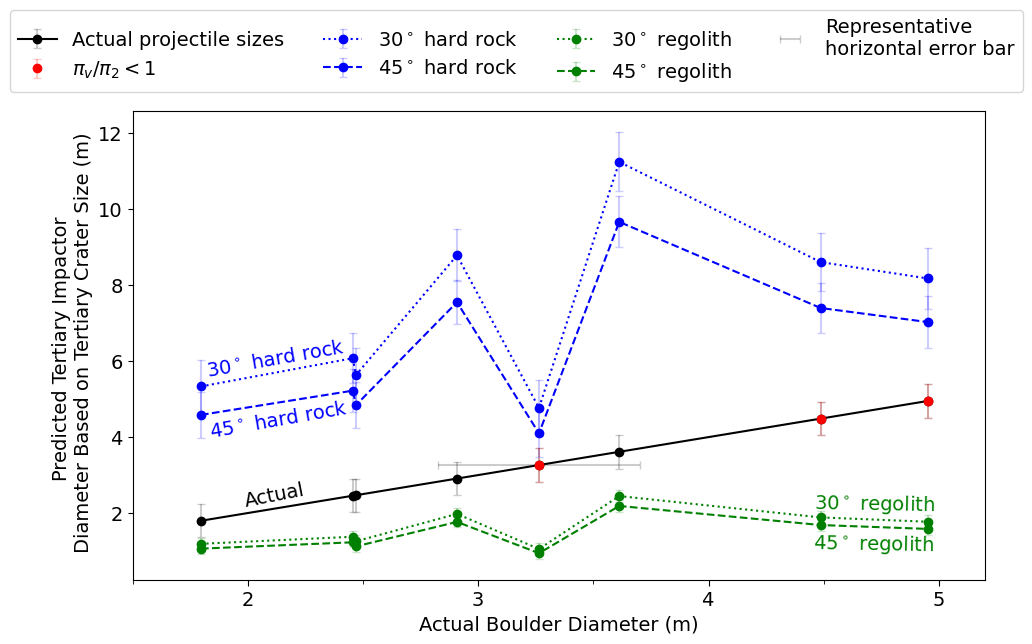

In [22]:
fig, ax = plt.subplots(figsize=(11, 7))

err = ax.errorbar(
    x, actual,
    yerr=xerr,
    fmt="ko-", label="Actual projectile sizes",
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


err = ax.errorbar(
    x[displaced_idx], actual[displaced_idx],
    yerr=xerr[displaced_idx],
    fmt="o", color="red", label=r"$\pi_v/\pi_2<1$", zorder=5,
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


err = ax.errorbar(
    x, rock30,

    yerr=np.array(
        udf_plot["UNC calculated fragment diameter [m] theta=30 deg, material=hard rock"]
    ),
    fmt="o:", color="blue", label=r"$30^\circ$ hard rock",
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


err = ax.errorbar(
    x, rock45,

    yerr=np.array(
        udf_plot["UNC calculated fragment diameter [m] theta=45 deg, material=hard rock"]
    ),
    fmt="o--", color="blue", label=r"$45^\circ$ hard rock",
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


err = ax.errorbar(
    x, rego30,

    yerr=np.array(
        udf_plot["UNC calculated fragment diameter [m] theta=30 deg, material=regolith"]
    ),
    fmt="o:", color="green", label=r"$30^\circ$ regolith",
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


err = ax.errorbar(
    x, rego45,

    yerr=np.array(
        udf_plot["UNC calculated fragment diameter [m] theta=45 deg, material=regolith"]
    ),
    fmt="o--", color="green", label=r"$45^\circ$ regolith",
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)

err = ax.errorbar(
    actual[4], actual[4],
    xerr=xerr[4],
    fmt="k", label="Representative\nhorizontal error bar", linestyle='none',
    capsize=3, capthick=1
)
fade_errorbars(err, alpha=0.2)


#rock30 (above & parallel)
x_mid_rock30 = (x[0] + x[1]) / 2
y_mid_rock30 = (rock30[0] + rock30[1]) / 2
# angle_rock30 = np.degrees(np.arctan2(rock30[1] - rock30[0], x[1] - x[0]))
angle_rock30 = 10
ax.text(x_mid_rock30, y_mid_rock30 + 0.1, r"$30^\circ$ hard rock",
        rotation=angle_rock30, rotation_mode='anchor', ha='center', va='bottom', fontsize=14, color="blue")

# rock45 (below & parallel)
x_mid_rock45 = (x[0] + x[1]) / 2
y_mid_rock45 = (rock45[0] + rock45[1]) / 2
# angle_rock45 = np.degrees(np.arctan2(rock45[1] - rock45[0], x[1] - x[0]))
angle_rock45 = 10
ax.text(x_mid_rock45, y_mid_rock45 - 0.2, r"$45^\circ$ hard rock",
        rotation=angle_rock45, rotation_mode='anchor', ha='center', va='top', fontsize=14, color="blue")

# rego30 (above & parallel)
x_mid_rego30 = (x[-1] + x[-2]) / 2
y_mid_rego30 = (rego30[-1] + rego30[-2]) / 2
# angle_rego30 = np.degrees(np.arctan2(rego30[1] - rego30[0], x[1] - x[0]))
angle_rego30 = -1
ax.text(x_mid_rego30, y_mid_rego30 + 0.1, r"$30^\circ$ regolith",
        rotation=angle_rego30, rotation_mode='anchor', ha='center', va='bottom', fontsize=14, color="green")

# rego45 (below & parallel)
x_mid_rego45 = (x[-1] + x[-2]) / 2
y_mid_rego45 = (rego45[-1] + rego45[-2]) / 2
# angle_rego45 = np.degrees(np.arctan2(rego45[1] - rego45[0], x[1] - x[0]))
angle_rego45 = -1
ax.text(x_mid_rego45, y_mid_rego45 - 0.15, r"$45^\circ$ regolith",
        rotation=angle_rego45, rotation_mode='anchor', ha='center', va='top', fontsize=14, color="green")

# Actual (above & parallel)
x_mid_actual = (x[0] + x[1]) / 2
y_mid_actual = (actual[0] + actual[1]) / 2
# angle_actual = np.degrees(np.arctan2(actual[1] - actual[0], x[1] - x[0]))
angle_actual = 11
ax.text(x_mid_actual, y_mid_actual + 0.1, "Actual",
        rotation=angle_actual, rotation_mode='anchor', ha='center', va='bottom', fontsize=14, color="black")


ax.set_xlabel("Actual Boulder Diameter (m)")
ax.set_ylabel("Predicted Tertiary Impactor \n Diameter Based on Tertiary Crater Size (m)")

ax.set_xlim(1.5, 5.2)

ax.xaxis.set_major_locator(FixedLocator([2, 3, 4, 5]))
ax.xaxis.set_major_formatter(FormatStrFormatter('%d'))

ax.xaxis.set_minor_locator(FixedLocator([1.5,2.5,3.5,4.5]))
ax.xaxis.set_minor_formatter(NullFormatter())

ax.yaxis.set_major_formatter(ScalarFormatter())
ax.ticklabel_format(axis='y', style='plain', useOffset=False)

ax.tick_params(axis='x', which='minor', length=3)
ax.tick_params(axis='x', which='major', length=4)


ax.legend(
    loc="lower center",
    bbox_to_anchor=(0.45, 1.02),
    ncol=4,
    frameon=True
)

plt.subplots_adjust(top=0.78)

plt.show()

Velocity histograms

Our points each have some spread. Need to MC sample around each velo value, assuming normal distribution with avg of the velo val and stdev of the unc associated w/ that velo value. Then we sample 10,000 times and plot those 10,000 samples for each velo pt on the histogram. It prolly won't look much different than the regular histogram bc our uncs are small compared to the size b/n bins, but I'm doing it this way to include the unc in some way

In [ ]:
color30 = "#0072B2"  #blue
color45 = "#D55E00"  #orange

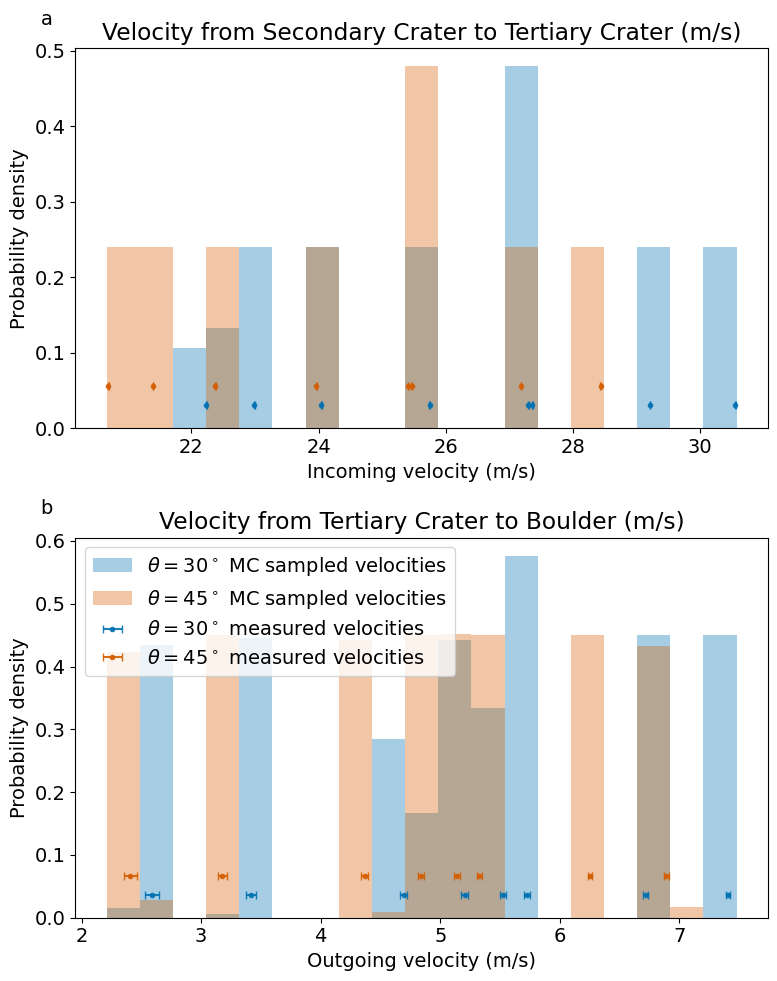

In [28]:
def plot_mc_hist(ax, vals30, unc30, vals45, unc45, title, xlabel, panel_label, show_legend=False):
    #MC sampling each point to give it a spread
    rng = np.random.default_rng(80303)
    n_samples_per_point = 10000

    samples30 = np.concatenate([
        rng.normal(loc=v, scale=u, size=n_samples_per_point)
        for v, u in zip(vals30, unc30)
    ])

    samples45 = np.concatenate([
        rng.normal(loc=v, scale=u, size=n_samples_per_point)
        for v, u in zip(vals45, unc45)
    ])

    #histogram bins
    all_samples = np.concatenate([samples30, samples45])
    bins = np.linspace(np.nanmin(all_samples), np.nanmax(all_samples), 20)

    ax.hist(
        samples30,
        bins=bins,
        density=True,
        color=color30,
        alpha=0.35,
        label=r"$\theta = 30^\circ$ MC sampled velocities"
    )

    ax.hist(
        samples45,
        bins=bins,
        density=True,
        color=color45,
        alpha=0.35,
        label=r"$\theta = 45^\circ$ MC sampled velocities"
    )

    ymax = ax.get_ylim()[1]

    y30 = np.full_like(vals30, 0.06 * ymax)
    y45 = np.full_like(vals45, 0.11 * ymax)

    ax.errorbar(
        vals30,
        y30,
        xerr=unc30,
        fmt=".",
        color=color30,
        ecolor=color30,
        capsize=3,
        alpha=0.9,
        label=r"$\theta = 30^\circ$ measured velocities"
    )

    ax.errorbar(
        vals45,
        y45,
        xerr=unc45,
        fmt=".",
        color=color45,
        ecolor=color45,
        capsize=3,
        alpha=0.9,
        label=r"$\theta = 45^\circ$ measured velocities"
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Probability density")
    if show_legend:
        ax.legend()

    ax.text(
        -0.05, 1.1, panel_label,
        transform=ax.transAxes,
        ha="left", va="top",
        fontsize=14
    )


#data
entervelo30 = np.array([_nan_if_none(v) for v in df_plot["velocity from sec to tert [m/s], theta=30 deg"]], dtype=float)
enteruncvelo30 = np.array([_nan_if_none(v) for v in udf_plot["UNC velocity from sec to tert [m/s], theta=30 deg"]], dtype=float)
entervelo45 = np.array([_nan_if_none(v) for v in df_plot["velocity from sec to tert [m/s], theta=45 deg"]], dtype=float)
enteruncvelo45 = np.array([_nan_if_none(v) for v in udf_plot["UNC velocity from sec to tert [m/s], theta=45 deg"]], dtype=float)

velo30 = np.array([_nan_if_none(v) for v in df_plot["velocity from tert to boulder [m/s], theta=30 deg"]], dtype=float)
uncvelo30 = np.array([_nan_if_none(v) for v in udf_plot["UNC velocity from tert to boulder [m/s], theta=30 deg"]], dtype=float)
velo45 = np.array([_nan_if_none(v) for v in df_plot["velocity from tert to boulder [m/s], theta=45 deg"]], dtype=float)
uncvelo45 = np.array([_nan_if_none(v) for v in udf_plot["UNC velocity from tert to boulder [m/s], theta=45 deg"]], dtype=float)


#fig
fig, axes = plt.subplots(2, 1, figsize=(8, 10))

plot_mc_hist(
    axes[0],
    entervelo30, enteruncvelo30,
    entervelo45, enteruncvelo45,
    title="Velocity from Secondary Crater to Tertiary Crater (m/s)",
    xlabel="Incoming velocity (m/s)",
    panel_label="a",
    show_legend=False
)

plot_mc_hist(
    axes[1],
    velo30, uncvelo30,
    velo45, uncvelo45,
    title="Velocity from Tertiary Crater to Boulder (m/s)",
    xlabel="Outgoing velocity (m/s)",
    panel_label="b",
    show_legend=True
)

plt.tight_layout()
plt.show()